# 01 — Análise Exploratória de Dados (EDA)

**Projeto:** predição de diabetes com classificação supervisionada.
**Dataset:** `data/raw/diabetes_pt.csv` (tradução para o português do *Pima Indians Diabetes Dataset*).

Objetivos deste notebook:

1. Entender a estrutura, os tipos e as estatísticas dos dados.
2. Encontrar valores ausentes, inválidos ou problemáticos. Em especial, verificar se alguns **zeros são, na verdade, medições ausentes**.
3. Estudar distribuições, outliers, correlações e a relação de cada preditor com o alvo `Resultado`.
4. Transformar essas observações em **decisões de pré-processamento justificadas** (tabela-resumo na §10).

> **Nota metodológica.** As seções 1–8 são *descritivas* e usam o dataset completo. Essa é a prática usual, porque elas apenas descrevem os dados e não ajustam nenhum modelo. Na §9 comparamos estratégias de pré-processamento treinando modelos de fato, por isso essa seção usa **apenas o conjunto de treino** (com validação cruzada). O conjunto de teste permanece intocado até a avaliação final, na Fase 3.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.colors import ListedColormap
from scipy import stats

from diabetes.config import FEATURES, RANDOM_SEED, TABLES_DIR, TARGET, TEST_SIZE, ZERO_AS_MISSING
from diabetes.data import load_raw, zeros_to_nan
from diabetes.plotting import CLASS_COLORS, CLASS_LABELS, DIVERGING_CMAP, NEUTRAL, apply_style, save_fig

apply_style()
pd.set_option("display.precision", 3)
TABLES_DIR.mkdir(parents=True, exist_ok=True)

df = load_raw()

## 1. Estrutura do dataset

In [2]:
structure = pd.DataFrame({
    "tipo": df.dtypes.astype(str),
    "valores_distintos": df.nunique(),
    "nulos": df.isna().sum(),
})
print(f"Dimensões: {df.shape[0]} linhas x {df.shape[1]} colunas | linhas duplicadas: {df.duplicated().sum()}")
display(df.head())
structure

Dimensões: 768 linhas x 9 colunas | linhas duplicadas: 0


,Gavidez,Glicose,PressaoArterial,Espesura_da_Pele,Insulina,IMC,Diabetes_Hereditaria,Idade,Resultado
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


,tipo,valores_distintos,nulos
Gavidez,int64,17,0
Glicose,int64,136,0
PressaoArterial,int64,47,0
Espesura_da_Pele,int64,51,0
Insulina,int64,186,0
IMC,float64,248,0
Diabetes_Hereditaria,float64,517,0
Idade,int64,52,0
Resultado,int64,2,0


**Observações**

- 768 linhas e 9 colunas: 8 preditores mais o alvo `Resultado`, conforme o enunciado.
- Todas as colunas são numéricas (`int64` ou `float64`). **Não há preditores categóricos**, então não é necessária nenhuma codificação (one-hot etc.).
- **Não há valores `NaN`** nem **linhas duplicadas**. Como a §4 mostra, "nenhum NaN" *não* significa "nenhum dado ausente".
- `Resultado` está armazenado como inteiro 0/1, mas é um **rótulo de classe**, não uma quantidade. Isso importa no Orange: se a coluna não for declarada *categórica* no widget File, o Orange trata o problema como regressão.

## 2. Estatística descritiva

In [3]:
desc = df.describe().T.rename(columns={
    "count": "contagem", "mean": "média", "std": "desvio_padrão", "min": "mín",
    "25%": "Q1 (25%)", "50%": "mediana", "75%": "Q3 (75%)", "max": "máx"})
desc["n_zeros"] = (df == 0).sum()
desc["assimetria"] = df.skew()
desc.to_csv(TABLES_DIR / "estatistica_descritiva_bruta.csv")
desc

,contagem,média,desvio_padrão,mín,Q1 (25%),mediana,Q3 (75%),máx,n_zeros,assimetria
Gavidez,768.0,3.845,3.370,0.000,1.000,3.000,6.000,17.00,111,0.902
Glicose,768.0,120.895,31.973,0.000,99.000,117.000,140.250,199.00,5,0.174
PressaoArterial,768.0,69.105,19.356,0.000,62.000,72.000,80.000,122.00,35,-1.844
Espesura_da_Pele,768.0,20.536,15.952,0.000,0.000,23.000,32.000,99.00,227,0.109
Insulina,768.0,79.799,115.244,0.000,0.000,30.500,127.250,846.00,374,2.272
IMC,768.0,31.993,7.884,0.000,27.300,32.000,36.600,67.10,11,-0.429
Diabetes_Hereditaria,768.0,0.472,0.331,0.078,0.244,0.372,0.626,2.42,0,1.920
Idade,768.0,33.241,11.760,21.000,24.000,29.000,41.000,81.00,0,1.130
Resultado,768.0,0.349,0.477,0.000,0.000,0.000,1.000,1.00,500,0.635


**Observações**

- `Glicose`, `PressaoArterial`, `Espesura_da_Pele`, `Insulina` e `IMC` têm **mínimo 0**. Uma pessoa viva não pode ter glicose, pressão diastólica, dobra cutânea ou IMC iguais a zero. Esses zeros são examinados na §4.
- O **primeiro quartil de `Insulina` é 0**, ou seja, pelo menos um quarto dos valores é zero. `Espesura_da_Pele` se comporta da mesma forma.
- `Insulina` tem dispersão muito grande (desvio-padrão 115, máximo 846) e forte assimetria à direita. `Diabetes_Hereditaria` também é assimétrica à direita.
- `Idade` vai de 21 a 81 anos. O estudo original incluiu apenas mulheres com 21 anos ou mais, o que limita a generalização dos resultados.
- `Gavidez` chega a 17. É incomum, mas possível: o registro com 17 gestações pertence a uma mulher de 47 anos.

## 3. Distribuição do alvo e desbalanceamento de classes

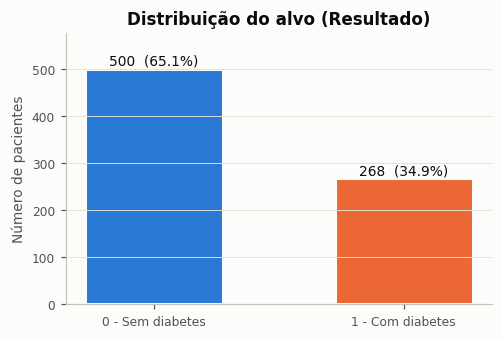

Razão de desbalanceamento (0:1) = 1.87 : 1
Acurácia do baseline de classe majoritária = 0.651


In [4]:
counts = df[TARGET].value_counts().sort_index()
share = counts / counts.sum()

fig, ax = plt.subplots(figsize=(5, 3.2))
bars = ax.bar([CLASS_LABELS[c] for c in counts.index], counts.values,
              color=[CLASS_COLORS[c] for c in counts.index], width=0.55, edgecolor="#fcfcfb", linewidth=2)
for bar, n, p in zip(bars, counts.values, share.values):
    ax.text(bar.get_x() + bar.get_width() / 2, n + 8, f"{n}  ({p:.1%})", ha="center", fontsize=9, color="#0b0b0b")
ax.set_ylabel("Número de pacientes")
ax.set_title("Distribuição do alvo (Resultado)")
ax.set_ylim(0, counts.max() * 1.15)
ax.grid(axis="x", visible=False)
save_fig(fig, "01_distribuicao_alvo")
plt.show()

print(f"Razão de desbalanceamento (0:1) = {counts[0] / counts[1]:.2f} : 1")
print(f"Acurácia do baseline de classe majoritária = {share.max():.3f}")

**Conceito: por que o desbalanceamento importa.** Um "modelo" trivial que sempre prevê *sem diabetes* já atinge **65,1% de acurácia**, mas seu **recall é 0**, porque ele nunca detecta nenhuma paciente diabética. Portanto:

- A acurácia sozinha é enganosa aqui. Qualquer modelo real precisa superar claramente **0,651** e deve ser julgado pelo **recall, pela precisão e pelo F1** da classe 1.
- O desbalanceamento é **moderado** (1,87 : 1), não extremo. Técnicas de reamostragem como SMOTE não são necessárias. A **divisão estratificada** (e a validação cruzada estratificada) basta para manter cerca de 35% de positivos em cada subconjunto.

## 4. Valores zero: observações legítimas ou medições ausentes?

**Conceito: mecanismos de dados ausentes.** A estatística distingue três casos:

- **MCAR** (*missing completely at random*): a ausência não tem relação com nenhuma variável.
- **MAR** (*missing at random*): a ausência depende de *outras* variáveis observadas.
- **MNAR** (*missing not at random*): a ausência depende do próprio valor que falta.

O mecanismo importa. Sob MCAR, uma imputação simples é praticamente inofensiva. Se a ausência estiver relacionada ao alvo, o próprio fato de o valor faltar pode carregar informação preditiva.

Primeiro: um zero é **fisiologicamente possível** em cada coluna?

| Coluna | Zero é plausível? | Justificativa |
|---|---|---|
| `Gavidez` | **Sim** | Zero gestações é comum. |
| `Glicose` | Não | Glicose plasmática 0 é incompatível com a vida. |
| `PressaoArterial` | Não | Pressão diastólica 0 é impossível em uma paciente viva. |
| `Espesura_da_Pele` | Não | Uma dobra cutânea sempre tem alguma espessura. |
| `Insulina` | Não | A insulina sérica 2 h após sobrecarga de glicose nunca é exatamente 0. |
| `IMC` | Não | IMC = peso / altura²; só é 0 se o peso for 0. |
| `Diabetes_Hereditaria` | — | Não há zeros (mínimo 0,078). |
| `Idade` | — | Não há zeros (mínimo 21). |

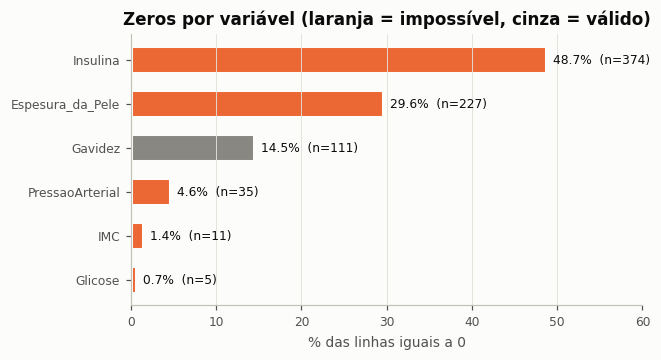

,n_zeros,pct_zeros,zero_e_ausente
Insulina,374,48.698,True
Espesura_da_Pele,227,29.557,True
Gavidez,111,14.453,False
PressaoArterial,35,4.557,True
IMC,11,1.432,True
Glicose,5,0.651,True
Diabetes_Hereditaria,0,0.000,False
Idade,0,0.000,False


In [5]:
zero_table = pd.DataFrame({
    "n_zeros": (df[FEATURES] == 0).sum(),
    "pct_zeros": (df[FEATURES] == 0).mean() * 100,
    "zero_e_ausente": [c in ZERO_AS_MISSING for c in FEATURES],
}).sort_values("n_zeros", ascending=False)
zero_table.to_csv(TABLES_DIR / "contagem_zeros.csv")

plot_df = zero_table[zero_table["n_zeros"] > 0].iloc[::-1]
fig, ax = plt.subplots(figsize=(6, 3.2))
colors = ["#eb6834" if m else NEUTRAL for m in plot_df["zero_e_ausente"]]
ax.barh(plot_df.index, plot_df["pct_zeros"], color=colors, height=0.6, edgecolor="#fcfcfb", linewidth=2)
for y, (pct, n) in enumerate(zip(plot_df["pct_zeros"], plot_df["n_zeros"])):
    ax.text(pct + 0.8, y, f"{pct:.1f}%  (n={n})", va="center", fontsize=8, color="#0b0b0b")
ax.set_xlabel("% das linhas iguais a 0")
ax.set_title("Zeros por variável (laranja = impossível, cinza = válido)")
ax.set_xlim(0, 60)
ax.grid(axis="y", visible=False)
save_fig(fig, "02_zeros_por_variavel")
plt.show()
zero_table

**Como os zeros se distribuem entre as linhas?** Se os valores ausentes se concentram nas mesmas pacientes, isso diz algo sobre *por que* eles faltam.

Linhas por quantidade de campos ausentes:
0    392
1    142
2    199
3     28
4      7

Linhas com pelo menos um valor ausente: 376 de 768 (49.0%)

Coocorrência de ausência em Espesura_da_Pele e Insulina:


Insulina ausente,False,True
Pele ausente,,
False,394,147
True,0,227


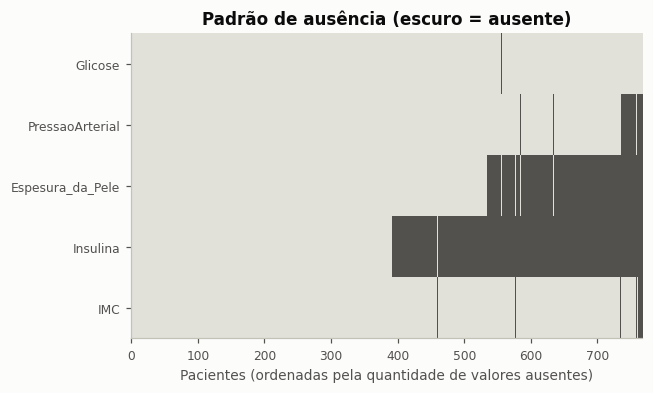

In [6]:
df_nan = zeros_to_nan(df)                     # zeros impossíveis -> NaN (etapa sem estado)
miss = df_nan[ZERO_AS_MISSING].isna()

n_missing_per_row = miss.sum(axis=1)
print("Linhas por quantidade de campos ausentes:")
print(n_missing_per_row.value_counts().sort_index().to_string())
print(f"\nLinhas com pelo menos um valor ausente: {miss.any(axis=1).sum()} de {len(df)} ({miss.any(axis=1).mean():.1%})")
print("\nCoocorrência de ausência em Espesura_da_Pele e Insulina:")
display(pd.crosstab(miss["Espesura_da_Pele"], miss["Insulina"],
                    rownames=["Pele ausente"], colnames=["Insulina ausente"]))

# Matriz de ausência: uma linha por paciente, ordenadas pela quantidade de valores ausentes.
order = n_missing_per_row.sort_values(kind="stable").index
fig, ax = plt.subplots(figsize=(6, 3.6))
ax.imshow(miss.loc[order].T.values, aspect="auto", interpolation="nearest",
          cmap=ListedColormap(["#e1e0d9", "#52514e"]))
ax.set_yticks(range(len(ZERO_AS_MISSING)), ZERO_AS_MISSING)
ax.set_xlabel("Pacientes (ordenadas pela quantidade de valores ausentes)")
ax.set_title("Padrão de ausência (escuro = ausente)")
ax.grid(False)
save_fig(fig, "03_padrao_ausencia")
plt.show()

**Observações**

- **376 das 768 linhas (49%)** têm pelo menos um valor ausente. Excluir todas as linhas incompletas (*exclusão listwise*) descartaria cerca de metade do dataset, o que **não é aceitável**.
- **Todas as 227 linhas sem `Espesura_da_Pele` também estão sem `Insulina`.** Esse padrão estruturado sugere que as duas medições costumavam ser omitidas juntas na coleta, por exemplo como parte da mesma etapa do exame. Não se trata de ruído aleatório em campos isolados. (É uma inferência a partir do padrão; a documentação do dataset não confirma isso.)
- `Glicose` (5) e `IMC` (11) têm pouquíssimos valores ausentes, então o tratamento escolhido tem pouco efeito sobre eles.

**Próxima pergunta: a ausência está relacionada ao alvo?** Se, por exemplo, as diabéticas tivessem insulina ausente com mais frequência, então "ausente" seria um sinal, e uma variável *indicadora de ausência* poderia ajudar.

**Conceito: teste qui-quadrado / teste exato de Fisher.** Ambos testam se a taxa de positivos é a mesma com o valor ausente ou presente. Um p-valor pequeno (< 0,05) sugeriria associação. O teste de Fisher serve de verificação, porque `Glicose` tem apenas 5 valores ausentes, poucos demais para a aproximação do qui-quadrado.

In [7]:
rows = []
for col in ZERO_AS_MISSING:
    is_missing = miss[col]
    table = pd.crosstab(is_missing, df[TARGET])
    rows.append({
        "variável": col,
        "n_ausentes": int(is_missing.sum()),
        "taxa_pos_se_ausente": df.loc[is_missing, TARGET].mean(),
        "taxa_pos_se_presente": df.loc[~is_missing, TARGET].mean(),
        "p_qui2": stats.chi2_contingency(table)[1],
        "p_fisher": stats.fisher_exact(table)[1],
    })
missing_vs_target = pd.DataFrame(rows).set_index("variável")
missing_vs_target.to_csv(TABLES_DIR / "ausencia_vs_alvo.csv")
missing_vs_target

,n_ausentes,taxa_pos_se_ausente,taxa_pos_se_presente,p_qui2,p_fisher
variável,,,,,
Glicose,5,0.400,0.349,1.000,1.000
PressaoArterial,35,0.457,0.344,0.233,0.203
Espesura_da_Pele,227,0.388,0.333,0.169,0.159
Insulina,374,0.369,0.330,0.290,0.289
IMC,11,0.182,0.351,0.394,0.346


**Observações**

- Em todas as colunas, a taxa de positivos **não difere significativamente** entre linhas com e sem o valor (todos os p > 0,15). As linhas sem `Insulina` têm 36,9% de positivos, contra 33,0% nas demais, uma diferença bem dentro da variação esperada pelo acaso.
- Portanto, a ausência **não carrega informação detectável sobre o alvo**. Isso é compatível com MCAR em relação a `Resultado` (embora não o prove) e prevê que variáveis indicadoras de ausência **não vão ajudar**. A §9 testa essa previsão.
- **Conclusão:** os zeros nas cinco colunas são **valores ausentes**; vamos convertê-los em `NaN` e imputá-los. A conversão para `NaN` não aprende nada com os dados, então fazê-la antes da divisão não vaza informação. A imputação *aprende* (por exemplo, a mediana), então deve ser ajustada apenas nos dados de treino.

## 5. Distribuições das variáveis numéricas

Primeiro os dados **brutos**, para ver como os zeros distorcem as distribuições.

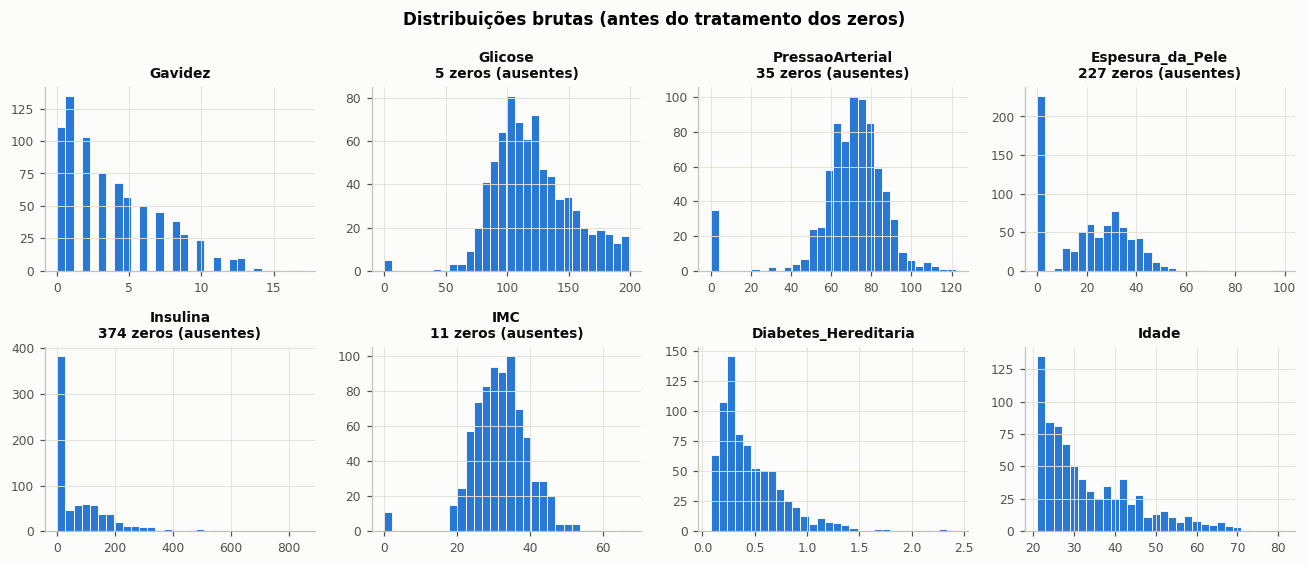

In [8]:
fig, axes = plt.subplots(2, 4, figsize=(12, 5.2))
for ax, col in zip(axes.flat, FEATURES):
    ax.hist(df[col], bins=30, color="#2a78d6", edgecolor="#fcfcfb", linewidth=0.6)
    n0 = (df[col] == 0).sum()
    if col in ZERO_AS_MISSING:
        ax.set_title(f"{col}\n{n0} zeros (ausentes)", fontsize=9)
    else:
        ax.set_title(col, fontsize=9)
    ax.set_ylabel("")
fig.suptitle("Distribuições brutas (antes do tratamento dos zeros)", fontsize=11, fontweight="semibold")
fig.tight_layout()
save_fig(fig, "04_histogramas_brutos")
plt.show()

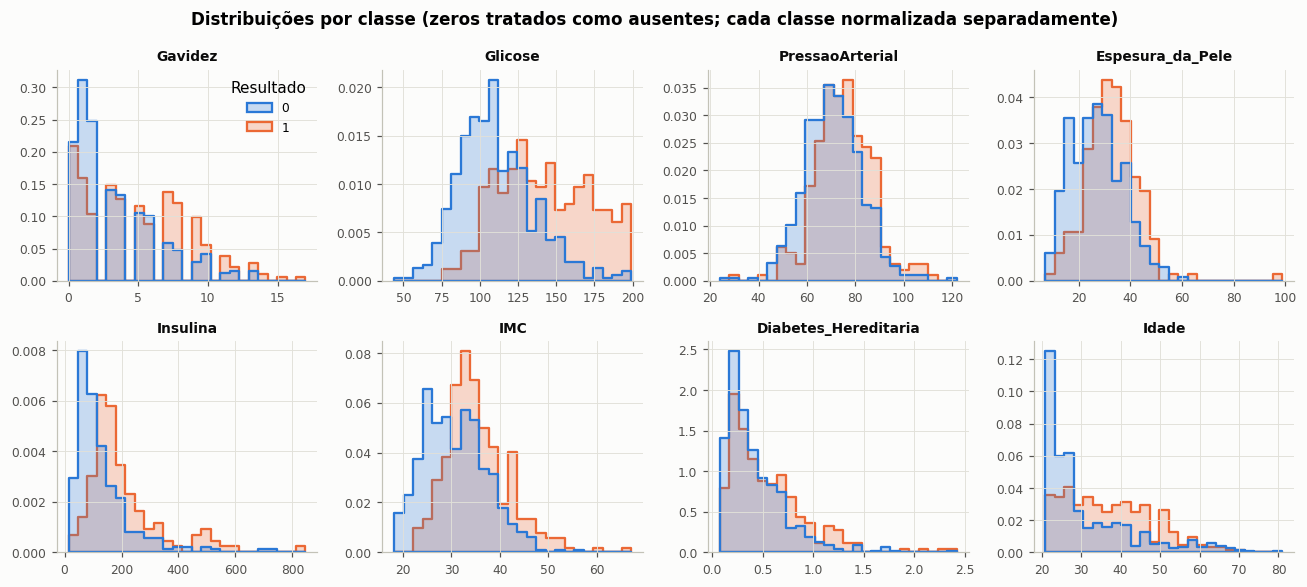

,assimetria_bruta,assimetria_zeros_como_nan
Gavidez,0.902,0.902
Glicose,0.174,0.531
PressaoArterial,-1.844,0.134
Espesura_da_Pele,0.109,0.691
Insulina,2.272,2.166
IMC,-0.429,0.594
Diabetes_Hereditaria,1.920,1.920
Idade,1.130,1.130


In [9]:
fig, axes = plt.subplots(2, 4, figsize=(12, 5.4))
for ax, col in zip(axes.flat, FEATURES):
    sns.histplot(data=df_nan, x=col, hue=TARGET, palette=CLASS_COLORS, stat="density",
                 common_norm=False, element="step", fill=True, alpha=0.25, linewidth=1.5,
                 bins=25, ax=ax, legend=(col == FEATURES[0]))
    ax.set_title(col, fontsize=9)
    ax.set_xlabel("")
    ax.set_ylabel("")
legend = axes.flat[0].get_legend()
legend.set_title("Resultado")
fig.suptitle("Distribuições por classe (zeros tratados como ausentes; cada classe normalizada separadamente)",
             fontsize=11, fontweight="semibold")
fig.tight_layout()
save_fig(fig, "05_histogramas_por_classe")
plt.show()

skew = pd.DataFrame({"assimetria_bruta": df[FEATURES].skew(),
                     "assimetria_zeros_como_nan": df_nan[FEATURES].skew()})
skew

**Observações**

- Os zeros criam **picos artificiais** longe dos dados reais. Em `PressaoArterial`, os zeros sozinhos produzem uma forte assimetria à esquerda (**−1,84**). Quando são tratados como ausentes, a distribuição fica quase simétrica (**0,13**). Os zeros são distorções, não informação.
- Após a limpeza, `Glicose`, `PressaoArterial` e `IMC` ficam aproximadamente em forma de sino. `Insulina` (2,17), `Diabetes_Hereditaria` (1,92), `Idade` (1,13) e `Gavidez` (0,90) continuam **assimétricas à direita**.
- A assimetria é um dos motivos para imputar com a **mediana** em vez da média: a mediana não é puxada pela cauda longa.
- **Separação entre classes:** `Glicose` mostra o deslocamento mais claro (diabéticas têm glicose visivelmente mais alta). `IMC`, `Idade` e `Insulina` mostram deslocamentos moderados. Em todas as variáveis as duas classes **se sobrepõem bastante**, então nenhuma variável sozinha as separa, e não devemos esperar uma classificação quase perfeita.

## 6. Outliers

**Conceito: regra do IQR.** Um valor é marcado como outlier se estiver abaixo de Q1 − 1,5·IQR ou acima de Q3 + 1,5·IQR, onde IQR = Q3 − Q1 (intervalo interquartil). É a mesma regra usada pelos "bigodes" do boxplot. Um outlier é um valor *estatisticamente incomum*, **não necessariamente um erro**. Decidir qual dos dois ele é exige conhecimento do domínio.

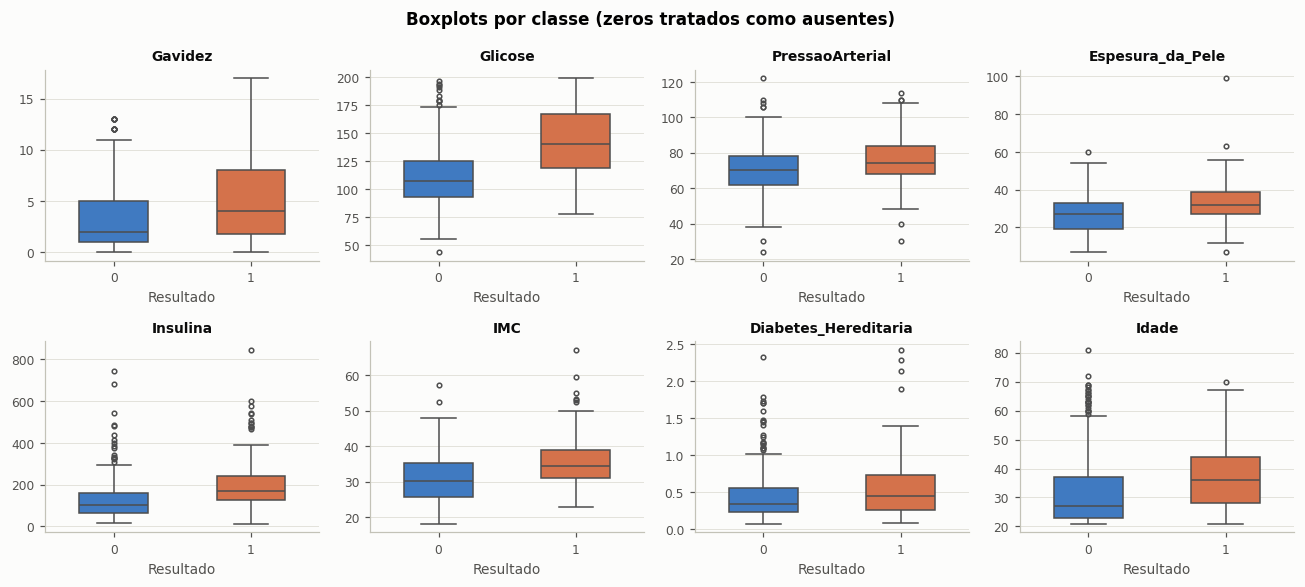

,limite_inferior,limite_superior,n_outliers,mín,máx
variável,,,,,
Diabetes_Hereditaria,-0.330,1.200,29,0.078,2.42
Insulina,-94.375,360.625,24,14.000,846.00
PressaoArterial,40.000,104.000,14,24.000,122.00
Idade,-1.500,66.500,9,21.000,81.00
IMC,13.850,50.250,8,18.200,67.10
Gavidez,-6.500,13.500,4,0.000,17.00
Espesura_da_Pele,1.000,57.000,3,7.000,99.00
Glicose,36.000,204.000,0,44.000,199.00


In [10]:
fig, axes = plt.subplots(2, 4, figsize=(12, 5.4))
for ax, col in zip(axes.flat, FEATURES):
    sns.boxplot(data=df_nan, x=TARGET, y=col, hue=TARGET, palette=CLASS_COLORS, legend=False,
                width=0.5, linewidth=1, fliersize=3, ax=ax)
    ax.set_title(col, fontsize=9)
    ax.set_xlabel("Resultado")
    ax.set_ylabel("")
fig.suptitle("Boxplots por classe (zeros tratados como ausentes)", fontsize=11, fontweight="semibold")
fig.tight_layout()
save_fig(fig, "06_boxplots_por_classe")
plt.show()

rows = []
for col in FEATURES:
    s = df_nan[col].dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    rows.append({"variável": col, "limite_inferior": low, "limite_superior": high,
                 "n_outliers": int(((s < low) | (s > high)).sum()), "mín": s.min(), "máx": s.max()})
outliers = pd.DataFrame(rows).set_index("variável").sort_values("n_outliers", ascending=False)
outliers.to_csv(TABLES_DIR / "outliers_iqr.csv")
outliers

In [11]:
# Inspeciona os casos mais extremos para julgar a plausibilidade clínica.
print("Maiores valores de Insulina:")
display(df_nan.nlargest(3, "Insulina")[["Insulina", "Glicose", "IMC", "Resultado"]])
print("Maiores valores de Espesura_da_Pele (os seguintes servem de comparação):")
display(df_nan.nlargest(3, "Espesura_da_Pele")[["Espesura_da_Pele", "IMC", "Resultado"]])
print("Menores valores de PressaoArterial:")
display(df_nan.nsmallest(3, "PressaoArterial")[["PressaoArterial", "Idade", "Resultado"]])

Maiores valores de Insulina:


,Insulina,Glicose,IMC,Resultado
13,846.0,189.0,30.1,1
228,744.0,197.0,36.7,0
247,680.0,165.0,52.3,0


Maiores valores de Espesura_da_Pele (os seguintes servem de comparação):


,Espesura_da_Pele,IMC,Resultado
579,99.0,34.7,1
445,63.0,59.4,1
57,60.0,46.8,0


Menores valores de PressaoArterial:


,PressaoArterial,Idade,Resultado
597,24.0,21,0
18,30.0,33,0
125,30.0,26,1


**Observações**

- Os outliers se concentram em `Diabetes_Hereditaria` (29), `Insulina` (24) e `PressaoArterial` (14). A maioria corresponde simplesmente às caudas longas vistas na §5.
- **Avaliação clínica dos extremos:**
  - `Insulina` = 846 junto com `Glicose` = 189 é uma combinação alta, mas **plausível** (forte resposta de insulina a uma glicose alta).
  - `Espesura_da_Pele` = 99 mm é **suspeito**, já que o valor seguinte é 63 mm. Pode ser um erro de registro, mas é uma única linha.
  - `PressaoArterial` = 24 mmHg é **implausivelmente baixa** para uma mulher de 21 anos, mas não temos como verificar.
  - `IMC` = 67,1 indica obesidade grave, o que é **plausível**.
- **Decisão: manter todos os outliers.** (1) A maioria são pacientes extremas plausíveis, e removê-las ensinaria ao modelo que essas pacientes não existem. (2) Com 768 linhas, cada registro conta. (3) Não temos verdade clínica para distinguir erros de extremos reais. (4) O Random Forest é insensível a valores extremos. A Regressão Logística e o KNN são um pouco afetados, mas a padronização limita essa influência. (5) Remover outliers do conjunto de *teste* tornaria a avaliação irrealisticamente otimista.
- *Melhoria opcional:* uma análise de sensibilidade (treinar com e sem as poucas linhas suspeitas) ou uma transformação logarítmica de `Insulina` e `Diabetes_Hereditaria`.

## 7. Correlações

**Conceito.** A correlação de *Pearson* mede associação **linear**. A de *Spearman* é a de Pearson calculada sobre os postos (*ranks*), então mede qualquer associação **monotônica** e é robusta a assimetria e outliers. Calculamos ambas nos dados limpos (zeros como `NaN`, exclusão par a par). Com um alvo binário, a correlação de Pearson é a correlação *ponto-bisserial*.

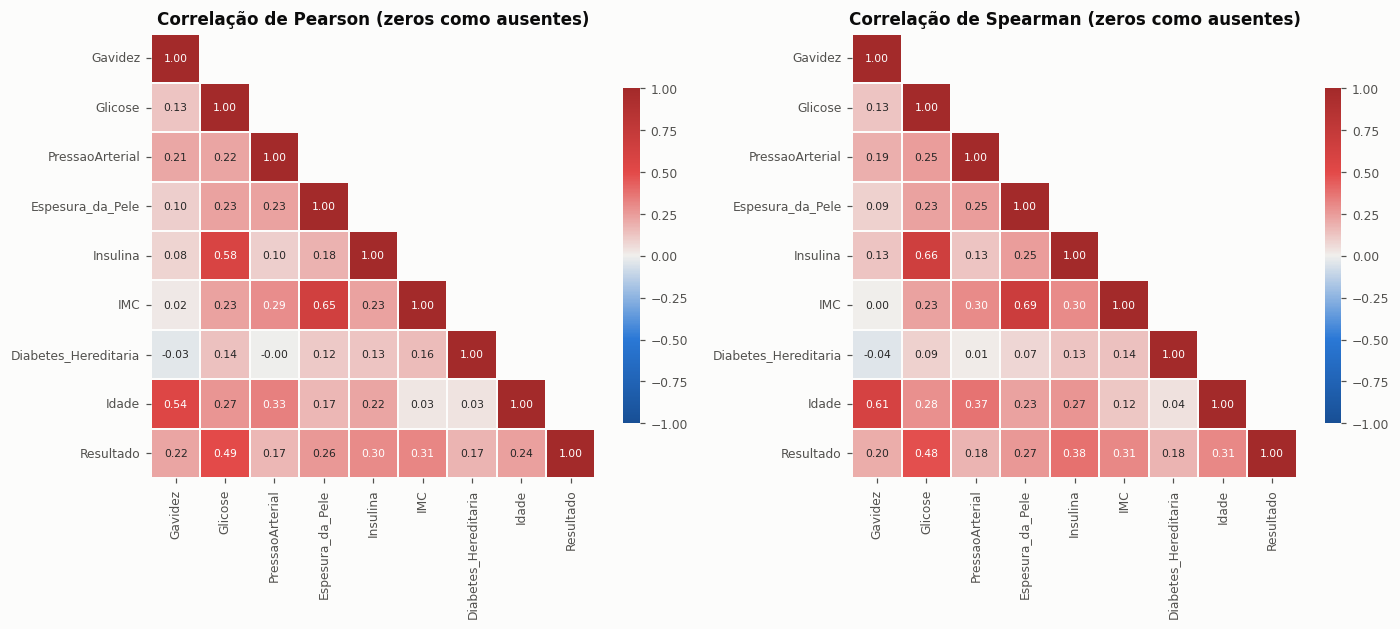

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.6))
for ax, (method, label) in zip(axes, [("pearson", "Pearson"), ("spearman", "Spearman")]):
    corr = df_nan.corr(method=method)
    mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
    sns.heatmap(corr, mask=mask, cmap=DIVERGING_CMAP, vmin=-1, vmax=1, center=0, annot=True, fmt=".2f",
                annot_kws={"size": 7}, linewidths=1, linecolor="#fcfcfb", square=True,
                cbar_kws={"shrink": 0.7}, ax=ax)
    ax.set_title(f"Correlação de {label} (zeros como ausentes)")
    ax.grid(False)
fig.tight_layout()
save_fig(fig, "07_mapas_correlacao")
plt.show()

In [13]:
# Tratar os zeros como ausentes muda a força da relação de cada variável com o alvo?
target_corr = pd.DataFrame({
    "pearson_com_zeros": df.corr()[TARGET],
    "pearson_zeros_como_nan": df_nan.corr()[TARGET],
    "spearman_zeros_como_nan": df_nan.corr(method="spearman")[TARGET],
}).drop(TARGET).sort_values("pearson_zeros_como_nan", ascending=False)
target_corr.to_csv(TABLES_DIR / "correlacao_com_alvo.csv")
target_corr

,pearson_com_zeros,pearson_zeros_como_nan,spearman_zeros_como_nan
Glicose,0.467,0.495,0.483
IMC,0.293,0.314,0.309
Insulina,0.131,0.303,0.377
Espesura_da_Pele,0.075,0.259,0.265
Idade,0.238,0.238,0.309
Gavidez,0.222,0.222,0.199
Diabetes_Hereditaria,0.174,0.174,0.175
PressaoArterial,0.065,0.171,0.177


**Observações**

- **Pares de preditores mais correlacionados:** `Espesura_da_Pele`–`IMC` (r = 0,65), `Glicose`–`Insulina` (0,58), `Gavidez`–`Idade` (0,54). Todos são fisiologicamente esperados: a dobra cutânea reflete a gordura corporal, a insulina responde à glicose e mulheres mais velhas tiveram mais gestações.
- **Nenhum par passa de 0,8**, então a **multicolinearidade não é grave**. Multicolinearidade forte desestabiliza principalmente a *interpretação* dos coeficientes da Regressão Logística, mais do que o desempenho preditivo. **As 8 variáveis são mantidas.**
- **Correlação com o alvo:** `Glicose` é de longe a mais forte (0,50), seguida de `IMC` (0,31), `Insulina` (0,30), `Espesura_da_Pele` (0,26) e `Idade` (0,24).
- **Os zeros escondiam sinal real.** Tratá-los como ausentes eleva a correlação com o alvo de `Espesura_da_Pele` de **0,07 para 0,26**, de `Insulina` de **0,13 para 0,30** e de `PressaoArterial` de **0,07 para 0,17**. É uma evidência forte de que os zeros são ruído, e não medições reais.
- `Insulina` tem correlação de Spearman (0,38) bem maior que a de Pearson (0,30): sua relação com o alvo é monotônica, mas não linear, como esperado dada a assimetria.

## 8. Relação de cada preditor com o alvo

**Conceito: teste U de Mann–Whitney.** Testa se uma classe tende a ter valores maiores que a outra. Diferentemente do teste t, não pressupõe distribuição normal, o que é adequado às nossas variáveis assimétricas.

In [14]:
rows = []
for col in FEATURES:
    neg = df_nan.loc[df[TARGET] == 0, col].dropna()
    pos = df_nan.loc[df[TARGET] == 1, col].dropna()
    rows.append({"variável": col, "mediana_classe0": neg.median(), "mediana_classe1": pos.median(),
                 "média_classe0": neg.mean(), "média_classe1": pos.mean(),
                 "p_mann_whitney": stats.mannwhitneyu(neg, pos).pvalue})
univariate = pd.DataFrame(rows).set_index("variável").sort_values("p_mann_whitney")
univariate.to_csv(TABLES_DIR / "testes_univariados.csv")
univariate

,mediana_classe0,mediana_classe1,média_classe0,média_classe1,p_mann_whitney
variável,,,,,
Glicose,107.000,140.000,110.644,142.320,1.305e-40
Idade,27.000,36.000,31.190,37.067,1.142e-17
IMC,30.100,34.300,30.860,35.407,1.819e-17
Insulina,102.500,169.500,130.288,206.846,7.477e-14
Espesura_da_Pele,27.000,32.000,27.235,33.000,6.961e-10
Gavidez,2.000,4.000,3.298,4.866,3.745e-08
Diabetes_Hereditaria,0.336,0.449,0.430,0.550,1.197e-06
PressaoArterial,70.000,74.500,70.877,75.321,1.629e-06


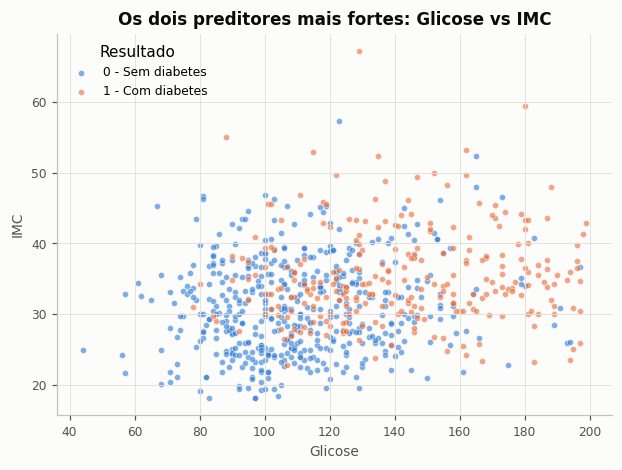

In [15]:
fig, ax = plt.subplots(figsize=(6.5, 4.5))
for cls in [0, 1]:
    sub = df_nan[df[TARGET] == cls]
    ax.scatter(sub["Glicose"], sub["IMC"], s=16, alpha=0.6, color=CLASS_COLORS[cls],
               edgecolor="#fcfcfb", linewidth=0.5, label=CLASS_LABELS[cls])
ax.set_xlabel("Glicose")
ax.set_ylabel("IMC")
ax.set_title("Os dois preditores mais fortes: Glicose vs IMC")
ax.legend(title="Resultado", loc="upper left")
save_fig(fig, "08_dispersao_glicose_imc")
plt.show()

**Observações**

- Todos os preditores diferem **significativamente** entre as classes (todos os p < 10⁻⁵). As diabéticas têm medianas maiores nas oito variáveis. A ordem concorda com as correlações: `Glicose` (p ≈ 10⁻⁴⁰) bem à frente, depois `IMC` e `Idade`.
- **Cuidado: significância estatística não é poder preditivo.** Com centenas de linhas, até um pequeno deslocamento se torna "significativo". O gráfico de dispersão é mais honesto: pacientes com glicose alta *e* IMC alto são, em sua maioria, diabéticas, mas a região intermediária é **muito misturada**. Todos os modelos vão errar ali, e os falsos negativos são os erros que mais nos preocupam.

## 9. Testando as opções de pré-processamento (somente dados de treino)

A §4 deixou várias formas candidatas de tratar os valores ausentes. Em vez de escolher por intuição, **medimos**.

**Por que usar apenas os dados de treino?** Se escolhêssemos a estratégia que pontua melhor no conjunto de *teste*, a nota de teste deixaria de ser uma estimativa imparcial do desempenho futuro: teríamos ajustado o pipeline a essas 154 pacientes. Isso é uma forma de **vazamento de dados** (*data leakage*). Por isso criamos a mesma divisão que a Fase 3 vai usar (80/20 estratificada, semente 42) e comparamos as estratégias com **validação cruzada dentro do conjunto de treino**.

**Conceito: validação cruzada k-fold estratificada repetida.** As 614 linhas de treino são divididas em 5 partes (*folds*), mantendo a proporção de classes em cada uma. Cada parte serve uma vez de validação enquanto as outras 4 treinam o modelo. Isso é repetido 10 vezes com embaralhamentos diferentes, gerando 50 notas por configuração. A **média** estima o desempenho, e o **desvio-padrão** mostra quanto ele varia. Se duas estratégias diferem menos que o desvio-padrão, a diferença provavelmente é ruído.

A imputação e a padronização ficam **dentro de um `Pipeline` do scikit-learn**, então são reajustadas apenas no fold de treino a cada iteração. É a mesma proteção contra vazamento que usaremos nos modelos finais.

Estratégias comparadas, usando três modelos de referência rápidos com hiperparâmetros padrão:

| Estratégia | Descrição |
|---|---|
| zeros brutos | Manter os zeros como estão (para medir o efeito de ignorar o problema). |
| média | Zeros → NaN, imputar com a média do treino. |
| mediana | Zeros → NaN, imputar com a mediana do treino. |
| mediana + indicadores | Mediana, mais uma coluna binária "estava ausente" para cada variável afetada. |
| remover Pele+Insulina | Remover as duas variáveis com mais ausências e imputar as demais com a mediana. |

In [16]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

X_train, X_test, y_train, y_test = train_test_split(
    df[FEATURES], df[TARGET], test_size=TEST_SIZE, stratify=df[TARGET], random_state=RANDOM_SEED)
print(f"Treino: {len(X_train)} linhas ({y_train.mean():.1%} positivas) | "
      f"Teste: {len(X_test)} linhas ({y_test.mean():.1%} positivas, {y_test.sum()} diabéticas) — teste NÃO usado aqui")

STRATEGIES = {
    "zeros brutos":          dict(to_nan=False, imputer=None,     indicators=False, drop=[]),
    "média":                 dict(to_nan=True,  imputer="mean",   indicators=False, drop=[]),
    "mediana":               dict(to_nan=True,  imputer="median", indicators=False, drop=[]),
    "mediana + indicadores": dict(to_nan=True,  imputer="median", indicators=True,  drop=[]),
    "remover Pele+Insulina": dict(to_nan=True,  imputer="median", indicators=False,
                                  drop=["Espesura_da_Pele", "Insulina"]),
}
MODELS = {
    "RegLog": (lambda: LogisticRegression(max_iter=1000), True),   # (fábrica, precisa_padronizar)
    "KNN":    (lambda: KNeighborsClassifier(), True),
    "RF":     (lambda: RandomForestClassifier(random_state=RANDOM_SEED), False),
}
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=RANDOM_SEED)
scoring = ["accuracy", "recall", "f1", "roc_auc"]
METRIC_NAMES = {"accuracy": "acurácia", "recall": "recall", "f1": "f1", "roc_auc": "roc_auc"}

rows = []
for strat_name, s in STRATEGIES.items():
    X = zeros_to_nan(X_train) if s["to_nan"] else X_train
    X = X.drop(columns=s["drop"])
    for model_name, (make_model, needs_scaling) in MODELS.items():
        steps = []
        if s["imputer"]:
            steps.append(SimpleImputer(strategy=s["imputer"], add_indicator=s["indicators"]))
        if needs_scaling:
            steps.append(StandardScaler())
        steps.append(make_model())
        res = cross_validate(make_pipeline(*steps), X, y_train, cv=cv, scoring=scoring)
        row = {"estratégia": strat_name, "modelo": model_name}
        for m in scoring:
            row[f"{METRIC_NAMES[m]}_média"] = res[f"test_{m}"].mean()
            row[f"{METRIC_NAMES[m]}_dp"] = res[f"test_{m}"].std()
        rows.append(row)

strategy_cv = pd.DataFrame(rows)
strategy_cv.to_csv(TABLES_DIR / "estrategias_preprocessamento_cv.csv", index=False)

# Visão compacta: "média ± desvio-padrão" por métrica
view = strategy_cv[["estratégia", "modelo"]].copy()
for m in METRIC_NAMES.values():
    view[m] = strategy_cv[f"{m}_média"].map("{:.3f}".format) + " ± " + strategy_cv[f"{m}_dp"].map("{:.3f}".format)
view.pivot(index="estratégia", columns="modelo", values="roc_auc").loc[list(STRATEGIES)]

Treino: 614 linhas (34.9% positivas) | Teste: 154 linhas (35.1% positivas, 54 diabéticas) — teste NÃO usado aqui


modelo,KNN,RF,RegLog
estratégia,,,
zeros brutos,0.782 ± 0.039,0.818 ± 0.035,0.831 ± 0.035
média,0.796 ± 0.038,0.820 ± 0.033,0.840 ± 0.030
mediana,0.793 ± 0.039,0.822 ± 0.031,0.840 ± 0.030
mediana + indicadores,0.780 ± 0.037,0.821 ± 0.032,0.836 ± 0.033
remover Pele+Insulina,0.802 ± 0.036,0.826 ± 0.031,0.843 ± 0.029


In [17]:
view.set_index(["modelo", "estratégia"]).sort_index(level=0, sort_remaining=False)

acurácia         recall             f1  \
modelo estratégia                                                           
KNN    zeros brutos           0.741 ± 0.032  0.548 ± 0.067  0.594 ± 0.054   
       média                  0.749 ± 0.037  0.593 ± 0.073  0.621 ± 0.056   
       mediana                0.742 ± 0.038  0.584 ± 0.066  0.612 ± 0.054   
       mediana + indicadores  0.744 ± 0.033  0.559 ± 0.075  0.601 ± 0.058   
       remover Pele+Insulina  0.754 ± 0.037  0.588 ± 0.077  0.624 ± 0.059   
RF     zeros brutos           0.761 ± 0.033  0.571 ± 0.072  0.623 ± 0.057   
       média                  0.759 ± 0.032  0.579 ± 0.078  0.624 ± 0.055   
       mediana                0.761 ± 0.033  0.585 ± 0.078  0.628 ± 0.057   
       mediana + indicadores  0.760 ± 0.035  0.573 ± 0.067  0.624 ± 0.054   
       remover Pele+Insulina  0.762 ± 0.030  0.583 ± 0.070  0.629 ± 0.053   
RegLog zeros brutos           0.783 ± 0.032  0.581 ± 0.071  0.650 ± 0.057   
       média                  0.784 ± 0.032  0.584 ± 0.075  0.652 ± 0.060   
       mediana                0.783 ± 0.031  0.581 ± 0.074  0.650 ± 0.059   
       mediana + indicadores  0.783 ± 0.033  0.585 ± 0.070  0.651 ± 0.058   
       remover Pele+Insulina  0.785 ± 0.031  0.584 ± 0.070  0.653 ± 0.056   

                                    roc_auc  
modelo estratégia                            
KNN    zeros brutos           0.782 ± 0.039  
       média                  0.796 ± 0.038  
       mediana                0.793 ± 0.039  
       mediana + indicadores  0.780 ± 0.037  
       remover Pele+Insulina  0.802 ± 0.036  
RF     zeros brutos           0.818 ± 0.035  
       média                  0.820 ± 0.033  
       mediana                0.822 ± 0.031  
       mediana + indicadores  0.821 ± 0.032  
       remover Pele+Insulina  0.826 ± 0.031  
RegLog zeros brutos           0.831 ± 0.035  
       média                  0.840 ± 0.030  
       mediana                0.840 ± 0.030  
       mediana + indicadores  0.836 ± 0.033  
       remover Pele+Insulina  0.843 ± 0.029

**Observações** (todos os números são estimativas de validação cruzada no conjunto de treino)

- **As diferenças entre estratégias são pequenas.** Para um mesmo modelo, a ROC-AUC varia no máximo cerca de 0,02, enquanto o desvio-padrão de cada estimativa é de cerca de 0,03. Estatisticamente, **nenhuma estratégia é claramente melhor**.
- **Tratar zeros como ausentes ajuda um pouco**, principalmente no **KNN**, cujos cálculos de distância são distorcidos por zeros falsos. Isso bate com a teoria: o KNN é o modelo que mais sofre com valores errados.
- **Indicadores de ausência não trazem ganho** e pioram levemente o KNN. Isso confirma a §4, onde a ausência não tinha relação com o alvo. **Rejeitado.**
- **Remover `Espesura_da_Pele` e `Insulina`** pontua um pouco melhor no KNN, dentro do ruído. Mas o enunciado diz que *todas as demais variáveis devem ser consideradas atributos preditores*, e o ganho não é significativo. **Rejeitado.** Vale mencionar isso na discussão do relatório.
- **Média vs. mediana:** os resultados são praticamente idênticos. Escolhemos a **mediana** pela robustez à assimetria e aos outliers (§5–6).
- ⚠️ **O recall é de apenas ~0,58** com o limiar de decisão padrão de 0,5: cerca de **4 em cada 10 diabéticas não são detectadas**. Esse será o ponto central da Fase 3, quando ajustarmos os modelos e discutirmos limiares.

## 10. Decisões de pré-processamento

| # | Decisão | Justificativa (seção) | Ajustado em |
|---|---|---|---|
| 1 | Substituir `0` por `NaN` em `Glicose`, `PressaoArterial`, `Espesura_da_Pele`, `Insulina`, `IMC`. Manter os zeros de `Gavidez`. | Fisiologicamente impossíveis (§4). Os zeros distorcem as distribuições (§5) e escondem a correlação com o alvo (§7). | Nada (etapa sem estado) |
| 2 | **Imputação pela mediana** nessas cinco colunas. | A exclusão listwise perderia 49% das linhas (§4). A mediana é robusta a assimetria e outliers (§5–6) e tem desempenho igual ao das alternativas (§9). | Somente treino (dentro do `Pipeline`) |
| 3 | **Sem variáveis indicadoras de ausência.** | A ausência não tem relação com o alvo (§4) e não traz ganho na validação cruzada (§9). | — |
| 4 | **Manter os 8 preditores.** | Exigido pelo enunciado. Sem multicolinearidade grave (§7). Remover variáveis não trouxe ganho significativo (§9). | — |
| 5 | **Manter os outliers** (sem remoção nem truncamento). | Em sua maioria, pacientes extremas plausíveis. Dataset pequeno. Removê-los do teste enviesaria a avaliação (§6). | — |
| 6 | **Padronização** (z-score: (x − μ)/σ) para todos os modelos. | Obrigatória para o KNN (distâncias) e para a rede neural (gradiente descendente). Recomendada para a Regressão Logística (a regularização trata todos os coeficientes igualmente). Inofensiva para o Random Forest, pois as árvores dependem só da ordem dos valores, que a padronização preserva. Usar o mesmo pré-processamento para todos os modelos mantém os pipelines do Python e do Orange simples e idênticos. | Somente treino |
| 7 | **Sem codificação.** | Não há preditores categóricos (§1). | — |
| 8 | **Sem reamostragem (ex.: SMOTE).** Divisão e validação cruzada estratificadas. Recall, precisão e F1 da classe 1. | Desbalanceamento moderado, 1,87 : 1 (§3). | — |

**Notas para o Orange (Fase 4):** declarar `Resultado` como categórica (§1). Até onde sei, o widget *Impute* do Orange oferece **média**, mas não mediana; isso será verificado na Fase 4. Se for o caso, há duas opções fiéis: (a) definir, para cada coluna, um valor fixo de imputação igual à mediana do treino calculada no Python; ou (b) usar imputação pela média no Orange e documentar a diferença, que é desprezível (a §9 mostra média ≈ mediana).

**Melhorias opcionais (além do enunciado):** transformação logarítmica de `Insulina` e `Diabetes_Hereditaria`; imputação baseada em modelo (KNN ou imputador iterativo); análise de sensibilidade aos outliers; pesos de classe e ajuste do limiar de decisão (a discutir na Fase 3).